# 01 — CIC-IDS2017 flows: exploration and timestamp check

CIC-IDS2017 records five working days (3–7 July 2017) of a small enterprise network. Each row is a network flow with its endpoints, a timestamp, about 80 statistics and a label. This notebook checks the data before modelling, with a focus on the timestamps, because the graph windows and both evaluation protocols depend on them.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
cfg = yaml.safe_load(Path('configs/experiment.yaml').read_text())
metrics = json.loads(Path('results/metrics.json').read_text())
from src.data import load_cic, find_column
flows = load_cic(cfg['data']['path'])
print(f"{len(flows):,} labelled flows, {int(flows['_target'].sum()):,} attacks ({flows['_target'].mean():.1%})")

/content/graph-network-intrusion-gnn/src/data.py:99: UserWarning: Dropping 288602 rows with missing labels.
  warnings.warn(f"Dropping {(~keep).sum()} rows with missing labels.")


2,830,743 labelled flows, 557,646 attacks (19.7%)


## Attack types per day

Each attack type happens on a single day. This is why a purely chronological split (protocol A) tests attacks that were never seen in training.

In [2]:
table = pd.crosstab(flows['_attack_type'], flows['_day']).reindex(columns=['Monday','Tuesday','Wednesday','Thursday','Friday'], fill_value=0)
display(table.sort_values(list(table.columns), ascending=False))

_day,Monday,Tuesday,Wednesday,Thursday,Friday
_attack_type,,,,,
Benign,529918,432074,440031,456752,414322
FTP-Patator,0,7938,0,0,0
SSH-Patator,0,5897,0,0,0
DoS Hulk,0,0,231073,0,0
DoS GoldenEye,0,0,10293,0,0
DoS slowloris,0,0,5796,0,0
DoS Slowhttptest,0,0,5499,0,0
Heartbleed,0,0,11,0,0
Web Attack - Brute Force,0,0,0,1507,0


## Timestamp repair

Several CSV files write afternoon times on a 12-hour clock without AM/PM (for example `7/7/2017 3:56` for 15:56). The loader shifts every hour before 08:00 by 12 hours, since captures only cover working hours. The table below compares the repaired attack times with the schedule published by the dataset authors; matching windows confirm the repair.

,day,attack,first flow,last flow,flows,documented (CIC)
0,Friday,Bot,09:34,12:59,1966,10:02–11:02
1,Friday,DDoS,15:56,16:16,128027,15:56–16:16
2,Friday,PortScan,13:05,15:23,158930,13:55–14:35
3,Thursday,Infiltration,14:19,15:45,36,14:19–15:45
4,Thursday,Web Attack - Brute Force,09:15,10:00,1507,09:20–10:00
5,Thursday,Web Attack - Sql Injection,10:40,10:42,21,10:40–10:42
6,Thursday,Web Attack - XSS,10:15,10:35,652,10:15–10:35
7,Tuesday,FTP-Patator,09:17,10:30,7938,09:20–10:20
8,Tuesday,SSH-Patator,14:09,15:11,5897,14:00–15:00
9,Wednesday,DoS GoldenEye,11:10,11:19,10293,11:10–11:23


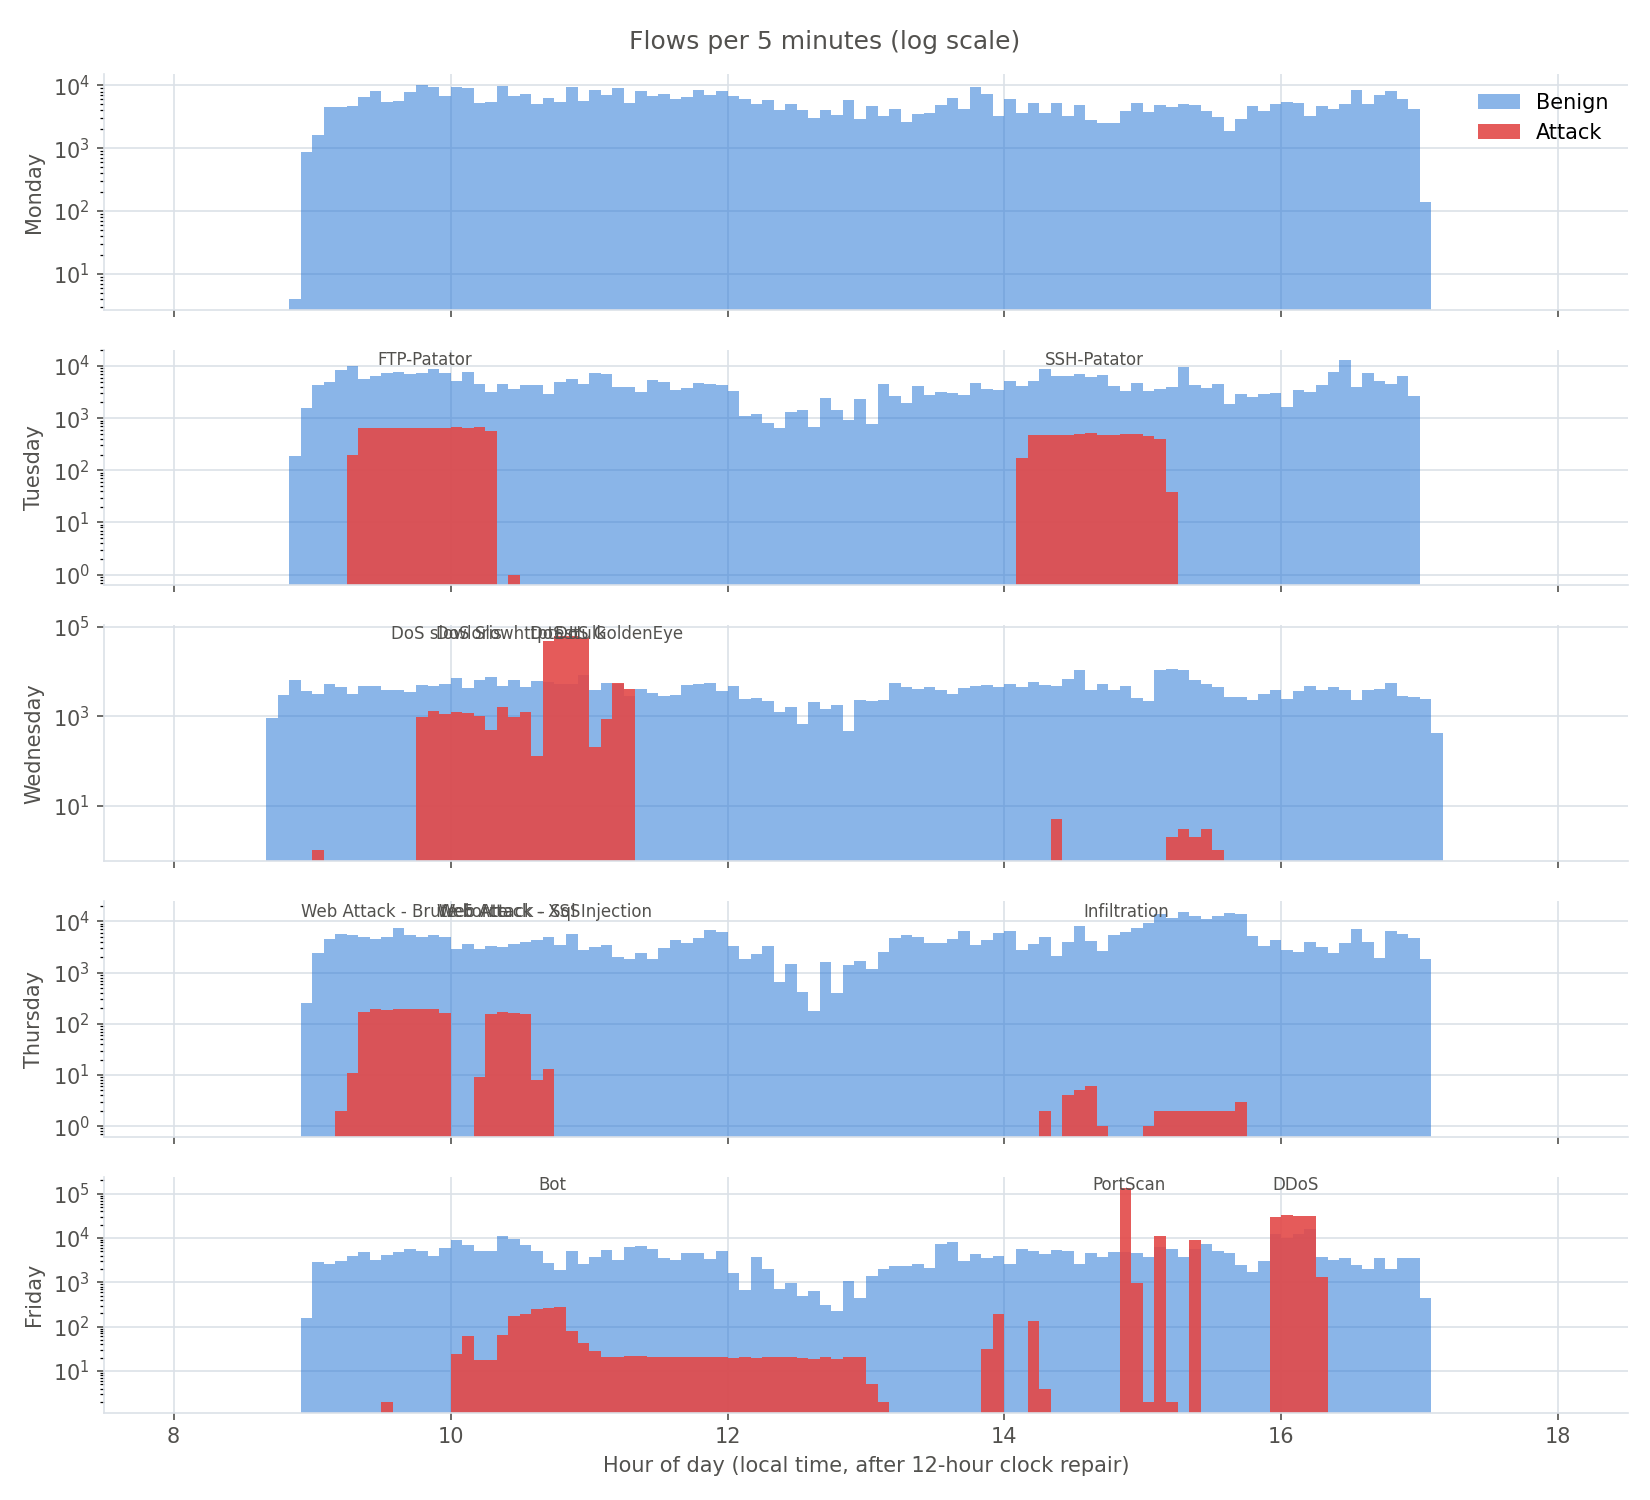

In [3]:
documented = {
 ('Tuesday','FTP-Patator'):'09:20–10:20', ('Tuesday','SSH-Patator'):'14:00–15:00',
 ('Wednesday','DoS slowloris'):'09:47–10:10', ('Wednesday','DoS Slowhttptest'):'10:14–10:35', ('Wednesday','DoS Hulk'):'10:43–11:00',
 ('Wednesday','DoS GoldenEye'):'11:10–11:23', ('Wednesday','Heartbleed'):'15:12–15:32',
 ('Thursday','Web Attack - Brute Force'):'09:20–10:00', ('Thursday','Web Attack - XSS'):'10:15–10:35', ('Thursday','Web Attack - Sql Injection'):'10:40–10:42',
 ('Thursday','Infiltration'):'14:19–15:45', ('Friday','Bot'):'10:02–11:02', ('Friday','PortScan'):'13:55–14:35', ('Friday','DDoS'):'15:56–16:16'}
sched = pd.DataFrame(metrics['dataset']['attack_schedule_after_repair'])
sched['documented (CIC)'] = [documented.get((d, a), '–') for d, a in zip(sched['_day'], sched['_attack_type'])]
sched = sched.rename(columns={'_day':'day','_attack_type':'attack','min':'first flow','max':'last flow','size':'flows'})
display(sched)
display(Image(filename='results/timeline.png'))

## Top talkers

IP addresses are used only to build the graph (hosts become nodes); they never enter the model as numeric features.

In [4]:
display(flows['Source IP'].value_counts().head(8).rename('outgoing flows').to_frame())
display(flows.loc[flows['_target']==1, 'Source IP'].value_counts().head(5).rename('outgoing attack flows').to_frame())

,outgoing flows
Source IP,
172.16.0.1,559247
192.168.10.3,298990
192.168.10.8,215280
192.168.10.5,170110
192.168.10.9,152536
192.168.10.12,146252
192.168.10.15,146036
192.168.10.14,140992


,outgoing attack flows
Source IP,
172.16.0.1,555641
205.174.165.73,705
192.168.10.15,371
192.168.10.8,307
192.168.10.9,226


## Heavy-tailed features

Counters such as bytes, packets and durations span many orders of magnitude. The preprocessing applies `log1p` to them, then standard scaling, fitted on training flows only.

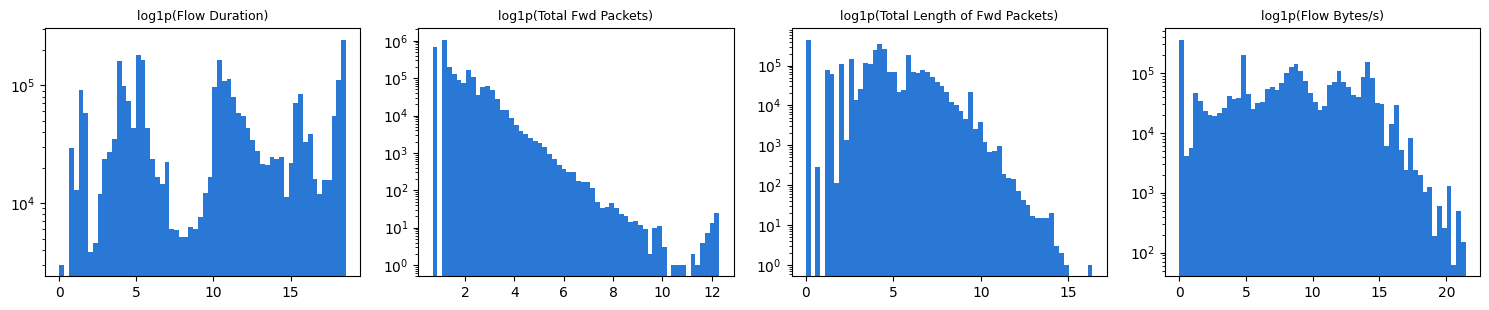

In [5]:
cols = ['Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Flow Bytes/s']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, c in zip(axes, cols):
    v = flows[c].replace([np.inf, -np.inf], np.nan).dropna().clip(lower=0)
    ax.hist(np.log1p(v), bins=60, color='#2a78d6'); ax.set_title(f'log1p({c})', fontsize=9); ax.set_yscale('log')
plt.tight_layout()

## Splits used by the experiments

In [6]:
rows = []
for proto in ('protocol_a', 'protocol_b'):
    for part, s in metrics[proto]['splits'].items():
        rows.append({'protocol': proto, 'split': part, 'flows': s['flows'], 'attacks': s['attacks'], 'windows': s['windows'],
                     'attack types': ', '.join(k for k in s['attack_types'] if k != 'Benign')})
display(pd.DataFrame(rows))

,protocol,split,flows,attacks,windows,attack types
0,protocol_a,train,839766,266507,300,"DoS Hulk, DoS GoldenEye, FTP-Patator, SSH-Pata..."
1,protocol_a,val,184949,2216,98,"Web Attack - Brute Force, Web Attack - XSS, In..."
2,protocol_a,test,467520,288923,98,"PortScan, DDoS, Bot"
3,protocol_b,train,1005634,433819,298,"DoS Hulk, PortScan, DDoS, DoS GoldenEye, FTP-P..."
4,protocol_b,val,272728,93776,99,"PortScan, DDoS, DoS Hulk, FTP-Patator, SSH-Pat..."
5,protocol_b,test,213873,30051,99,"PortScan, DDoS, SSH-Patator, FTP-Patator, Web ..."
